# 2016〜2026年 衆議院予算委員会 発言トピック・クラスタリング

11暦年のクリーニング済み68,948発言を共通の特徴空間で10クラスタに分類します。2026年は取得時点までの途中年です。

In [1]:
from pathlib import Path
import os
import sys

ROOT = Path.cwd()
if not (ROOT / 'cleaned').exists():
    ROOT = ROOT.parent
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.matplotlib'))
Path(os.environ['MPLCONFIGDIR']).mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(ROOT))
from clustering_2016 import (
    FIXED_K, RANDOM_STATE, apply_manual_labels, cluster_details, compare_k,
    export_results, load_input, reduce_dimensions, vectorize,
)

sns.set_theme(style='whitegrid')
mac_font_paths = list(Path('/System/Library/Fonts').glob('*角*W3.ttc'))
if not mac_font_paths:
    raise FileNotFoundError('macOSのヒラギノ角ゴシック W3が見つかりません')
font_manager.fontManager.addfont(str(mac_font_paths[0]))
MAC_JAPANESE_FONT = font_manager.FontProperties(fname=str(mac_font_paths[0])).get_name()
plt.rcParams['font.family'] = MAC_JAPANESE_FONT
plt.rcParams['axes.unicode_minus'] = False
OUTPUT_DIR = ROOT / 'analysis/clustering_2016_2026'
EXPECTED_BY_YEAR = {2016: 5928, 2017: 6283, 2018: 7434, 2019: 5985, 2020: 8056, 2021: 6269, 2022: 6451, 2023: 5744, 2024: 5896, 2025: 7449, 2026: 3453}
print(f'Matplotlib font: {MAC_JAPANESE_FONT} ({mac_font_paths[0]})')
RANDOM_STATE

Matplotlib font: Hiragino Sans (/System/Library/Fonts/ヒラギノ角ゴシック W3.ttc)


42

## 1. 年別入力の読込・検証

各年の件数、会議名、発言ID、本文を検証してから縦結合します。

In [2]:
frames = [
    load_input(ROOT / f'cleaned/speeches_{year}.jsonl', expected_rows=count)
    for year, count in EXPECTED_BY_YEAR.items()
]
df = pd.concat(frames, ignore_index=True, verify_integrity=True)
assert len(df) == 68948
assert df['speechID'].is_unique
assert set(df['year']) == set(EXPECTED_BY_YEAR)
year_counts = df.groupby('year', as_index=False).agg(speeches=('speechID', 'size'), speakers=('speaker', 'nunique'))
display(year_counts)
display(pd.Series({'rows': len(df), 'unique_speech_ids': df['speechID'].nunique(), 'years': df['year'].nunique(), 'review_flagged': int(df['review_flags'].map(bool).sum())}).to_frame('value'))

,year,speeches,speakers
0,2016,5928,211
1,2017,6283,218
2,2018,7434,235
3,2019,5985,196
4,2020,8056,228
5,2021,6269,251
6,2022,6451,255
7,2023,5744,228
8,2024,5896,279
9,2025,7449,374


,value
rows,68948
unique_speech_ids,68948
years,11
review_flagged,5141


## 2. 日本語処理、TF-IDF、次元削減

全年度をまとめてSudachiPyで正規化し、共通TF-IDF空間を作成して100次元へ圧縮します。

In [3]:
source_df = df.copy()
vectorizer, tfidf, keep_mask = vectorize(source_df)
zero_vector_records = source_df.loc[~keep_mask].copy()
zero_vector_records['exclusion_reason'] = 'zero_vector_after_tfidf'
df = source_df.loc[keep_mask].copy().reset_index(drop=True)
assert len(df) + len(zero_vector_records) == len(source_df)
assert not {'発言短文', '低情報発言'} & set(vectorizer.get_feature_names_out())
svd, reduced = reduce_dimensions(tfidf)
print(f'TF-IDF: {tfidf.shape[0]:,} rows × {tfidf.shape[1]:,} features')
print(f'SVD explained variance: {svd.explained_variance_ratio_.sum():.1%}')
print(f'Zero vectors excluded: {len(zero_vector_records):,}')
display(zero_vector_records[['speechID', 'date', 'year', 'speaker', 'speech_cleaned', 'exclusion_reason']])

TF-IDF: 68,209 rows × 20,000 features
SVD explained variance: 11.0%
Zero vectors excluded: 739


,speechID,date,year,speaker,speech_cleaned,exclusion_reason
32,119205261X00520161012_038,2016-10-12,2016,西村康稔,ありがとうございました。終わります。,zero_vector_after_tfidf
43,119205261X00520161012_050,2016-10-12,2016,赤羽一嘉,どうもありがとうございました。 以上で終わります。,zero_vector_after_tfidf
136,119205261X00520161012_172,2016-10-12,2016,山尾志桜里,ちょっと静かにしていただけますか。,zero_vector_after_tfidf
262,119205261X00520161012_319,2016-10-12,2016,高橋千鶴子,どこですか。,zero_vector_after_tfidf
284,119205261X00520161012_342,2016-10-12,2016,浦野靖人,時間が来ましたので、これで終わります。どうもありがとうございました。,zero_vector_after_tfidf
...,...,...,...,...,...,...
68750,122105261X00220260227_132,2026-02-27,2026,岡本三成,ありがとうございました。 終わります。,zero_vector_after_tfidf
68780,122105261X00220260227_165,2026-02-27,2026,長妻昭,総理、いかがですか。,zero_vector_after_tfidf
68816,122105261X00220260227_202,2026-02-27,2026,山本香苗,総理、いかがでしょうか。,zero_vector_after_tfidf
68822,122105261X00220260227_208,2026-02-27,2026,山本香苗,総理、いかがでしょうか。,zero_vector_after_tfidf


## 3. KMeans（10クラスタ固定）

2016〜2026年を一つのモデルで `k=10` に分類します。

In [4]:
scores, models = compare_k(reduced, candidates=[FIXED_K])
best_k = FIXED_K
model = models[best_k]
print(f'Fixed k={best_k}')
display(scores.style.format({'silhouette': '{:.4f}', 'inertia': '{:,.1f}'}))

Fixed k=10


,k,silhouette,inertia,smallest_cluster,largest_cluster
0,10,0.0311,"54,757.6",3004,17078


## 4. クラスタの解釈

特徴語、代表発言、主要話者、クラスタ規模を確認します。

,cluster,provisional_label,count,ratio,top_terms,representative_speech_ids
0,0,日本・アメリカ・我が国,6231,9.1%,日本 | アメリカ | 我が国 | 安全 | 日米 | 安全 保障 | 保障 | 世界 | 会談 | 対する | 米国 | 中国,121605261X00320241210_036 | 121705261X01220250218_172 | 119305261X00220170126_006 | 121705261X00220250131_033 | 121305261X00720240209_208
1,1,子供・教育・子育て,3060,4.5%,子供 | 教育 | 子育て | 無償化 | 支援 | 家庭 | 学校 | 世帯 | 子供達 | 政策 | 社会 | 少子化,120105261X01420200219_027 | 121105261X00820230208_047 | 121005261X00220221017_102 | 121005261X00620221125_091 | 121705261X01120250217_161
2,2,感染・接種・ワクチン,3921,5.7%,感染 | 接種 | ワクチン | 検査 | 医療 | 対策 | 状況 | 体制 | 拡大 | 感染 拡大 | コロナ | 感染症,120405261X01120210216_002 | 120805261X01020220204_002 | 120805261X00820220202_030 | 120105261X02420200520_002 | 120805261X00820220202_014
3,3,致す・行う・承知,10296,15.1%,致す | 行う | 承知 | 判断 | 検討 | 場合 | よる | 先程 | 関する | 具体的 | 基づく | 情報,121005261X00820221129_081 | 119805261X00920190218_381 | 121305261X01720240422_039 | 119605261X00420180202_131 | 121105261X01220230217_212
4,4,調査・行う・結果,3004,4.4%,調査 | 行う | 結果 | 調査 行う | 調査 結果 | 委員会 | 報告 | 統計 | 関する | 致す | 受ける | 対する,121305261X00920240214_292 | 120405261X01720210301_359 | 119605261X01220180215_051 | 119305261X00920170208_314 | 119605261X01220180215_037
5,5,予算・年度・補正,3408,5.0%,予算 | 年度 | 補正 | 補正 予算 | 令和 | 令和 年度 | 計上 | 基金 | 審議 | 対策 | 予備費 | 年度 予算,122105261X01120260313_074 | 122105261X00420260303_304 | 122105261X00220260227_078 | 120105261X01920200427_002 | 120105261X00320200128_491
6,6,経済・負担・賃金,7617,11.2%,経済 | 負担 | 賃金 | 上がる | 消費税 | 政策 | よる | 増える | 物価 | 国民 | 財政 | 賃上げ,121205261X00620231122_286 | 121905261X00720251210_380 | 119805261X00420190208_010 | 119605261X00520180205_271 | 121705261X00320250203_276
7,7,願う・宜しい・出る,17078,25.0%,願う | 宜しい | 出る | 事実 | 報告 | 委員会 | 委員長 | 知る | 受ける | 先程 | 呼ぶ | 認識,119605261X01320180219_248 | 119505261X00320171128_235 | 121105261X00420230201_133 | 122105261X01720260727_059 | 119805261X00220190204_234
8,8,議論・政治・自民党,5614,8.2%,議論 | 政治 | 自民党 | 議員 | 資金 | 政治 資金 | 国民 | 政党 | 選挙 | 総裁 | 政策 | 団体,121305261X01720240422_054 | 121305261X00720240209_294 | 121605261X00120241205_209 | 121305261X01420240226_084 | 121305261X00520240207_297
9,9,支援・地域・進める,7980,11.7%,支援 | 地域 | 進める | 参る | 取り組み | よる | 取り組む | 致す | 行う | 事業 | 活用 | 整備,119805261X01020190220_551 | 119005261X01420160218_162 | 121105261X00620230203_028 | 119005261X01420160218_158 | 121705261X01020250214_315


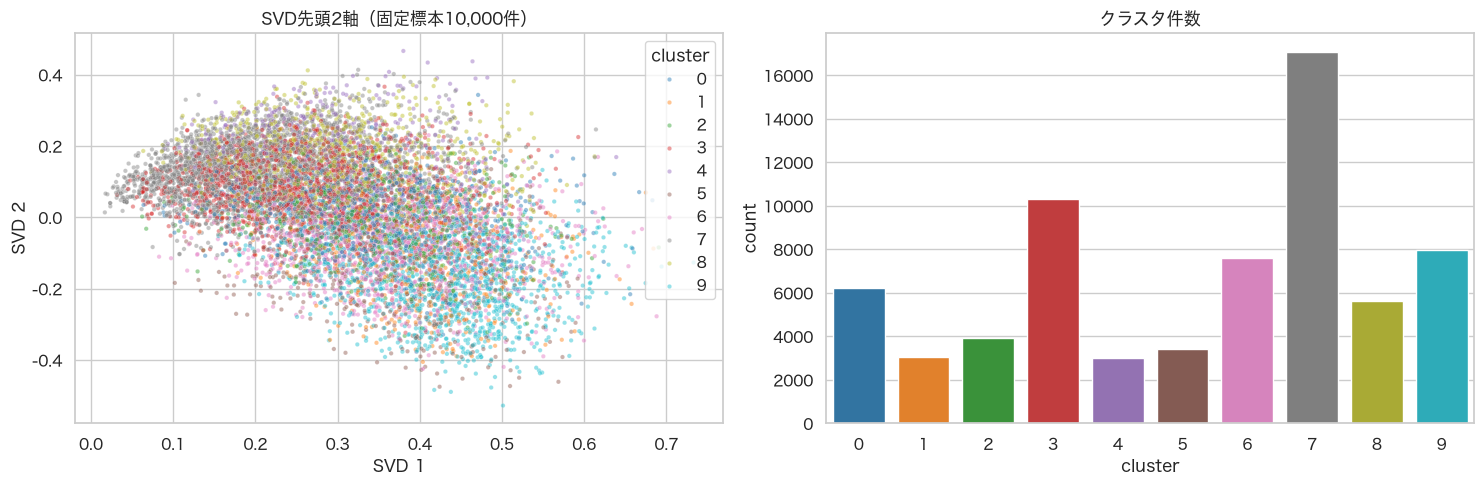

In [5]:
assignments, summary = cluster_details(df, tfidf, reduced, vectorizer, model)
display(summary.style.format({'ratio': '{:.1%}'}))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_sample = assignments.sample(n=min(10000, len(assignments)), random_state=RANDOM_STATE)
plot_idx = plot_sample.index.to_numpy()
sns.scatterplot(x=reduced[plot_idx, 0], y=reduced[plot_idx, 1], hue=plot_sample['cluster'], palette='tab10', s=10, alpha=.45, legend='full', ax=axes[0])
axes[0].set(title='SVD先頭2軸（固定標本10,000件）', xlabel='SVD 1', ylabel='SVD 2')
sns.barplot(data=summary, x='cluster', y='count', hue='cluster', palette='tab10', legend=False, ax=axes[1])
axes[1].set_title('クラスタ件数')
plt.tight_layout();

In [6]:
for cluster_id in summary['cluster']:
    row = summary.loc[summary['cluster'].eq(cluster_id)].iloc[0]
    members = assignments.loc[assignments['cluster'].eq(cluster_id)]
    representatives = members.nsmallest(5, 'centroid_distance')[['speechID', 'date', 'year', 'speaker', 'speech_cleaned', 'centroid_distance']]
    top_speakers = members['speaker'].value_counts().head(5).rename_axis('speaker').reset_index(name='count')
    print(f"\nCluster {cluster_id}: {row['provisional_label']} ({row['count']:,}件)")
    print(f"特徴語: {row['top_terms']}")
    display(top_speakers, representatives)


Cluster 0: 日本・アメリカ・我が国 (6,231件)
特徴語: 日本 | アメリカ | 我が国 | 安全 | 日米 | 安全 保障 | 保障 | 世界 | 会談 | 対する | 米国 | 中国


,speaker,count
0,安倍晋三,549
1,岸田文雄,500
2,石破茂,179
3,高市早苗,143
4,茂木敏充,138


,speechID,date,year,speaker,speech_cleaned,centroid_distance
52071,121605261X00320241210_036,2024-12-10,2024,中谷真一,自民党の中谷真一でございます。 まず冒頭、この度、私どもの事務所において不記載の問題がござい...,0.582696
61711,121705261X01220250218_172,2025-02-18,2025,櫛渕万里,アメリカだけでは抑止できないという発言、大変重要だと思います。おっしゃられたように、日米首脳...,0.623109
11784,119305261X00220170126_006,2017-01-26,2017,小野寺五典,今回は円高要因による一時的なものというふうに理解をしますし、また、現在の円・ドルベースを見れ...,0.624894
64510,121705261X00220250131_033,2025-01-31,2025,中曽根康隆,総理おっしゃるとおりで、自助あっての共助だと思います。 先日、私も、横田めぐみさんの弟さんと...,0.625795
55512,121305261X00720240209_208,2024-02-09,2024,太栄志,総理、分かりました。 ＵＮＲＷＡのことに関しては、是非ともタイミングを見計らって資金拠出を検...,0.629555



Cluster 1: 子供・教育・子育て (3,060件)
特徴語: 子供 | 教育 | 子育て | 無償化 | 支援 | 家庭 | 学校 | 世帯 | 子供達 | 政策 | 社会 | 少子化


,speaker,count
0,岸田文雄,265
1,安倍晋三,158
2,石破茂,66
3,加藤勝信,59
4,小倉將信,53


...

,speaker,count
0,岸田文雄,726
1,安倍晋三,495
2,石破茂,247
3,高市早苗,166
4,大西健介,129


,speechID,date,year,speaker,speech_cleaned,centroid_distance
52761,121305261X01720240422_054,2024-04-22,2024,赤羽一嘉,公明党の赤羽一嘉でございます。 本日は、二十五分という限られた時間でございますので、閣僚の皆...,0.708081
55595,121305261X00720240209_294,2024-02-09,2024,小野泰輔,時間が近いので、もうこれ以上同じことは繰り返しませんが、毎回原稿を読まずに同じ答弁をされてい...,0.711597
52509,121605261X00120241205_209,2024-12-05,2024,青柳仁士,是非、石破総理の思いで自民党を変えていただきたいなと私は個人的には思います。 そして、午前中...,0.714443
53421,121305261X01420240226_084,2024-02-26,2024,野田佳彦,私は、基本的には、説明できないようなお金が残っている、そういうことを、基本的にはやはり納税し...,0.718048
56309,121305261X00520240207_297,2024-02-07,2024,斎藤アレックス,教育無償化を実現する会の斎藤アレックスでございます。 日本維新の会との統一会派を代表して、本...,0.721088



Cluster 9: 支援・地域・進める (7,980件)
特徴語: 支援 | 地域 | 進める | 参る | 取り組み | よる | 取り組む | 致す | 行う | 事業 | 活用 | 整備


,speaker,count
0,岸田文雄,531
1,安倍晋三,363
2,高市早苗,205
3,加藤勝信,161
4,石破茂,127


,speechID,date,year,speaker,speech_cleaned,centroid_distance
22559,119805261X01020190220_551,2019-02-20,2019,高橋賢友,北海道経済連合会の高橋でございます。本日はよろしくお願い申し上げます。 本日は、田中団長を始...,0.622590
2682,119005261X01420160218_162,2016-02-18,2016,山名元,初めまして。原子力損害賠償・廃炉等支援機構の理事長を務めております山名元と申します。 本日は...,0.634233
50059,121105261X00620230203_028,2023-02-03,2023,松本剛明,ありがとうございます。 まず、先ほどの話、両大臣に答弁をということでございましたが、おっしゃ...,0.640576
2680,119005261X01420160218_158,2016-02-18,2016,渡邊博美,福島県商工会議所連合会会長の渡邊博美です。 本日は、衆議院予算委員会の地方公聴会で意見陳述を...,0.642358
62297,121705261X01020250214_315,2025-02-14,2025,芦谷茂,ただいま御紹介いただきました中国経済連合会会長の芦谷でございます。 本日は、このような意見陳...,0.643585


## 5. 年別クラスタ構成

2026年は途中年なので、他年との比率比較ではその点に注意します。

cluster,0,1,2,3,4,5,6,7,8,9
year,,,,,,,,,,
2016,488,193,36,1031,223,218,1283,1187,643,574
2017,627,251,19,1608,472,168,295,2058,295,402
2018,696,261,37,1080,540,235,466,2946,365,734
2019,507,168,65,860,464,118,640,2412,229,459
2020,375,184,1272,1642,128,260,393,2552,403,715
2021,396,168,1304,793,446,215,315,1617,262,685
2022,646,339,962,725,210,348,840,1120,450,755
2023,687,596,89,795,103,311,806,982,580,748
2024,394,310,28,601,203,242,667,922,1461,1022


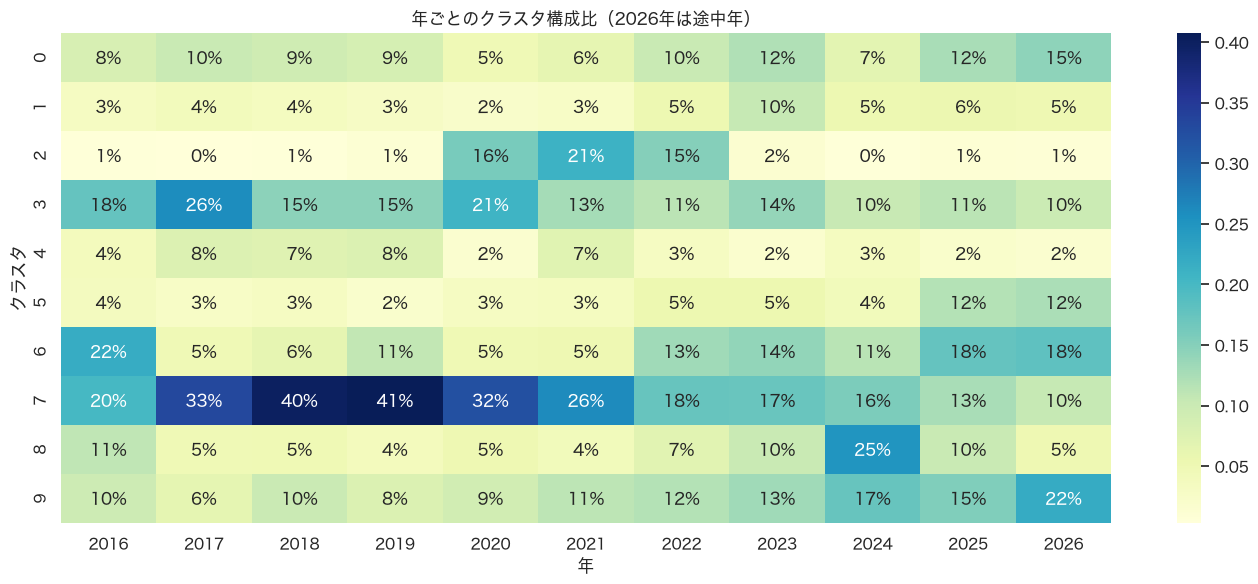

In [7]:
yearly_counts = pd.crosstab(assignments['year'], assignments['cluster'])
yearly_ratio = pd.crosstab(assignments['year'], assignments['cluster'], normalize='index')
display(yearly_counts)
plt.figure(figsize=(14, 6))
sns.heatmap(yearly_ratio.T, cmap='YlGnBu', annot=True, fmt='.0%')
plt.title('年ごとのクラスタ構成比（2026年は途中年）')
plt.xlabel('年')
plt.ylabel('クラスタ')
plt.tight_layout();

## 6. 人手によるラベル調整

代表発言を確認し、必要なクラスタだけ名称を上書きしてください。

In [8]:
MANUAL_CLUSTER_LABELS = {
    # 0: '社会保障・医療',
    # 1: '外交・安全保障',
}
assignments, summary = apply_manual_labels(assignments, summary, MANUAL_CLUSTER_LABELS)
display(summary[['cluster', 'cluster_label', 'count', 'ratio', 'top_terms']].style.format({'ratio': '{:.1%}'}))

,cluster,cluster_label,count,ratio,top_terms
0,0,日本・アメリカ・我が国,6231,9.1%,日本 | アメリカ | 我が国 | 安全 | 日米 | 安全 保障 | 保障 | 世界 | 会談 | 対する | 米国 | 中国
1,1,子供・教育・子育て,3060,4.5%,子供 | 教育 | 子育て | 無償化 | 支援 | 家庭 | 学校 | 世帯 | 子供達 | 政策 | 社会 | 少子化
2,2,感染・接種・ワクチン,3921,5.7%,感染 | 接種 | ワクチン | 検査 | 医療 | 対策 | 状況 | 体制 | 拡大 | 感染 拡大 | コロナ | 感染症
3,3,致す・行う・承知,10296,15.1%,致す | 行う | 承知 | 判断 | 検討 | 場合 | よる | 先程 | 関する | 具体的 | 基づく | 情報
4,4,調査・行う・結果,3004,4.4%,調査 | 行う | 結果 | 調査 行う | 調査 結果 | 委員会 | 報告 | 統計 | 関する | 致す | 受ける | 対する
5,5,予算・年度・補正,3408,5.0%,予算 | 年度 | 補正 | 補正 予算 | 令和 | 令和 年度 | 計上 | 基金 | 審議 | 対策 | 予備費 | 年度 予算
6,6,経済・負担・賃金,7617,11.2%,経済 | 負担 | 賃金 | 上がる | 消費税 | 政策 | よる | 増える | 物価 | 国民 | 財政 | 賃上げ
7,7,願う・宜しい・出る,17078,25.0%,願う | 宜しい | 出る | 事実 | 報告 | 委員会 | 委員長 | 知る | 受ける | 先程 | 呼ぶ | 認識
8,8,議論・政治・自民党,5614,8.2%,議論 | 政治 | 自民党 | 議員 | 資金 | 政治 資金 | 国民 | 政党 | 選挙 | 総裁 | 政策 | 団体
9,9,支援・地域・進める,7980,11.7%,支援 | 地域 | 進める | 参る | 取り組み | よる | 取り組む | 致す | 行う | 事業 | 活用 | 整備


## 7. CSV出力と最終検証

発言別結果、クラスタ要約、年別件数・構成比をUTF-8 BOM付きで保存します。

In [9]:
assert len(assignments) + len(zero_vector_records) == 68948
assert assignments['speechID'].is_unique
assert assignments['cluster'].notna().all()
assert set(assignments['cluster']) == set(range(10))
assert summary['count'].sum() == len(assignments)
export_results(assignments, summary, OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
zero_vector_records.to_csv(OUTPUT_DIR / 'excluded_zero_vectors.csv', index=False, encoding='utf-8-sig')
yearly_counts.to_csv(OUTPUT_DIR / 'yearly_cluster_counts.csv', encoding='utf-8-sig')
yearly_ratio.to_csv(OUTPUT_DIR / 'yearly_cluster_ratios.csv', encoding='utf-8-sig')
assert len(pd.read_csv(OUTPUT_DIR / 'speech_clusters.csv')) == len(assignments)
assert len(pd.read_csv(OUTPUT_DIR / 'excluded_zero_vectors.csv')) == len(zero_vector_records)
assert len(pd.read_csv(OUTPUT_DIR / 'cluster_summary.csv')) == 10
print(f'出力先: {OUTPUT_DIR}')
print(f'検証完了: 元{len(source_df):,}件、ゼロベクトル除外{len(zero_vector_records):,}件、学習対象{len(assignments):,}件、10クラスタ')

出力先: /Users/tasskkiu2/kokkai/analysis/clustering_2016_2026
検証完了: 元68,948件、ゼロベクトル除外739件、学習対象68,209件、10クラスタ
